# 9. Proposal items (train + validation only)

The project proposal commits to several things that notebooks 04–08 had not yet done, or had
done only partly. Each is handled here, on train / cross-validation / validation only:

| id | proposal wording | section |
|---|---|---|
| G3 | "apply a stratified split" | 9.1 |
| G5 | "High collinearity … Gram matrix which will require regularization" | 9.2 |
| G2 | "Hyperparameters will be selected using validation folds" | 9.3 |
| G1 | "tabular syntactic, rhetorical and n-gram representations" | 9.4 |
| G4 | "identify critical boundary arguments via active support vectors" | 9.5 |
| G6 | NLTK in the tool list; "remove proper nouns during text preprocessing" | 9.6 |
| G7 | "binary and multi-class detection … Ad Hominem, False Dilemma and Slippery Slope"; "accuracy metric against an imbalanced baseline" | 9.7 |

Choices made here are written to `results/selection.json` and evaluated once on test in
notebook 10. The test split is not loaded.

In [1]:
import sys, json, time, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, average_precision_score
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from src.config import RESULTS, FIGURES, SEED
from src.data import load_dataset, get_splits
from src.features import word_tfidf
from src.models import logreg, linear_svm
from src.evaluate import scores
from src.structural import structural_features, FEATURE_NAMES, TfidfPlusStructural
from src.text import mask_proper_nouns

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_va, Y_va, _ = S["val"]; del S["test"]
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr); B = vec.transform(X_va)
FOCUS = ["Slippery Slope", "Ad Hominem", "False Dilemma"]
sel_path = RESULTS / "selection.json"; sel = json.loads(sel_path.read_text())

## 9.1 (G3) Is the official split stratified?
The dataset's split is a hash of the normalised text, which guarantees that exact
duplicates never cross splits. We check whether it is also stratified, i.e. each label's
prevalence is about the same in every split.

In [2]:
prev = df.groupby("split")[LABELS].mean().T[["train", "val", "test"]]
prev["all"] = df[LABELS].mean()
prev["max |gap|"] = prev[["train", "val", "test"]].sub(prev["all"], axis=0).abs().max(axis=1)
prev.to_csv(RESULTS / "split_prevalence.csv")
print("largest prevalence gap over all labels and splits:", round(prev["max |gap|"].max(), 4))
prev.round(3)

largest prevalence gap over all labels and splits: 0.0181


split,train,val,test,all,max |gap|
Slippery Slope,0.274,0.277,0.276,0.274,0.003
Appeal to Authority,0.172,0.158,0.180,0.171,0.013
Bandwagon / Popularity,0.158,0.148,0.160,0.157,0.009
Hasty Generalization,0.140,0.120,0.118,0.136,0.018
False Cause / Causality,0.117,0.119,0.122,0.118,0.005
Appeal to Emotion,0.110,0.117,0.118,0.112,0.007
Composition,0.078,0.085,0.075,0.078,0.007
False Dilemma,0.075,0.079,0.083,0.076,0.007
Ad Hominem,0.067,0.073,0.068,0.067,0.006
Equivocation,0.051,0.046,0.049,0.050,0.005


The largest gap is under 2 percentage points, so the hash split is already close to
stratified. We keep it rather than drawing a fresh multilabel-stratified split, because a
fresh split would (a) allow exact duplicates across splits and (b) break comparability with
notebook 03. The 5-fold CV in 9.3 *is* multilabel-stratified.

## 9.2 (G5) Collinearity of the design matrix
For the 2,000 most frequent TF-IDF features we compute the condition number of X and of the
Gram matrix XᵀX (κ(XᵀX) = κ(X)²) and count near-duplicate feature pairs.

In [3]:
top = np.asarray((A > 0).sum(0)).ravel().argsort()[::-1][:2000]
Xd = A[:, top].toarray(); sv_ = np.linalg.svd(Xd, compute_uv=False)
kappa = sv_[0] / sv_[-1]
Cm = np.corrcoef(Xd, rowvar=False); np.fill_diagonal(Cm, 0); up = np.triu(np.abs(Cm), 1)
names = vec.get_feature_names_out()[top]
pairs = sorted(zip(*np.where(up > 0.95)), key=lambda ij: -up[ij])
print(f"κ(X) = {kappa:.3g}   κ(XᵀX) = {kappa**2:.3g}   smallest singular value = {sv_[-1]:.2e}")
print("feature pairs with |corr| > 0.95:", len(pairs))
pd.DataFrame([(names[i], names[j], round(up[i, j], 3)) for i, j in pairs[:10]], columns=["feature a", "feature b", "|corr|"])

κ(X) = 3.27e+17   κ(XᵀX) = 1.07e+35   smallest singular value = 6.14e-17
feature pairs with |corr| > 0.95: 81


,feature a,feature b,|corr|
0,unable,unable to,1.0
1,due to,due,1.0
2,incapable of,incapable,1.0
3,fossil fuels,fuels,1.0
4,tend,tend to,1.0
5,according,according to,1.0
6,a phd,phd,1.0
7,able,able to,1.0
8,laureate,nobel laureate,1.0
9,friend's,my friend's,1.0


κ(XᵀX) is far beyond 1/ε ≈ 4.5×10¹⁵ for float64, so XᵀX is numerically singular: the
unpenalised logistic-regression solution is not unique (many weight vectors fit equally
well). Pairs like "unable" / "unable to" are almost always present together. Adding a penalty
fixes this: ridge (L2) adds λI to the Hessian, making it positive definite, and spreads weight
across a correlated pair; Lasso (L1) keeps an essentially arbitrary one of the pair. This is
the proposal's collinearity claim, measured.

## 9.3 (G2) Hyperparameters chosen by validation folds
5-fold multilabel-stratified CV **on the training split**, with the vectoriser inside the
pipeline so every fold learns its own vocabulary. Selection rule: highest mean macro-F1.
The single validation split is then used as an independent check.

In [4]:
cv = list(MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X_tr, Y_tr))
def cv_score(model):
    s = cross_val_score(make_pipeline(word_tfidf(ngram_range=(1, 2)), model), X_tr, Y_tr, cv=cv, scoring="f1_macro")
    return s.mean(), s.std()
rows = []
for C in [0.1, 0.3, 1, 3, 10]:
    for cw in [None, "balanced"]:
        m, s = cv_score(linear_svm(C, cw)); rows.append({"family": "LinearSVM", "C": C, "class_weight": str(cw), "cv_macro_f1": m, "cv_sd": s})
for C in [10, 100, 1000]:
    m, s = cv_score(logreg("l1", C, "balanced")); rows.append({"family": "LR-L1", "C": C, "class_weight": "balanced", "cv_macro_f1": m, "cv_sd": s})
    m, s = cv_score(logreg("l2", C, "balanced")); rows.append({"family": "LR-L2", "C": C, "class_weight": "balanced", "cv_macro_f1": m, "cv_sd": s})
cvt = pd.DataFrame(rows); cvt.to_csv(RESULTS / "cv_grid_train.csv", index=False)
best_cv = cvt.sort_values("cv_macro_f1", ascending=False).groupby("family").head(1)
cmp = best_cv.assign(val_choice=[f"C={sel[f]['C']:g}, cw={sel[f]['class_weight']}" for f in best_cv.family])
cmp.round(4)

,family,C,class_weight,cv_macro_f1,cv_sd,val_choice
5,LinearSVM,1.0,balanced,0.8076,0.0084,"C=1, cw=balanced"
15,LR-L2,1000.0,balanced,0.8073,0.0074,"C=1000, cw=balanced"
14,LR-L1,1000.0,balanced,0.7887,0.0064,"C=1000, cw=balanced"


If the CV choice and the earlier validation-split choice agree, the earlier selection
stands and is now justified by the protocol the proposal promised. Where they disagree, the
CV choice wins (it averages over 5 × 11.5k training arguments instead of one 1.8k split) and
is written to `selection.json` below.

In [5]:
changed = []
for _, r in best_cv.iterrows():
    f = r["family"]
    if (float(sel[f]["C"]), str(sel[f]["class_weight"])) != (float(r["C"]), r["class_weight"]):
        changed.append(f)
    sel[f].update({"C": float(r["C"]), "class_weight": r["class_weight"], "cv_macro_f1": float(r["cv_macro_f1"]),
                   "selected_by": "5-fold multilabel-stratified CV on train"})
print("families whose choice changed under CV:", changed or "none")

families whose choice changed under CV: none


## 9.4 (G1) Structural / rhetorical tabular features
13 counts of argument patterns (`src/structural.py`): if–then consequence, causal chains,
either–or, universal quantifiers, authority words, popularity words, second person, insults,
causal connectives, negation, questions, exclamations, and log length. They are scaled with a
train-fitted `StandardScaler` and appended to TF-IDF with a weight w, chosen by the same CV.

In [6]:
s_cfg = sel["LinearSVM"]; cw = None if s_cfg["class_weight"] == "None" else "balanced"
srow = []
for w in [0.1, 0.3, 1.0, 3.0]:
    s = cross_val_score(make_pipeline(TfidfPlusStructural(weight=w), linear_svm(s_cfg["C"], cw)),
                        X_tr, Y_tr, cv=cv, scoring="f1_macro")
    srow.append({"weight": w, "cv_macro_f1": s.mean(), "cv_sd": s.std()})
srow = pd.DataFrame(srow)
base_cv = float(cvt[(cvt.family == "LinearSVM") & (cvt.C == s_cfg["C"]) & (cvt.class_weight == s_cfg["class_weight"])].cv_macro_f1.iloc[0])
print("TF-IDF only, same SVM, CV macro-F1:", round(base_cv, 4)); srow.round(4)

TF-IDF only, same SVM, CV macro-F1: 0.8076


,weight,cv_macro_f1,cv_sd
0,0.1,0.8076,0.0056
1,0.3,0.8079,0.0043
2,1.0,0.8100,0.0063
3,3.0,0.8100,0.0063


In [7]:
# Tie rule: among weights within 1e-4 of the best CV score, take the smallest (simplest model;
# larger weights also make liblinear converge far more slowly).
w_best = float(srow[srow.cv_macro_f1 >= srow.cv_macro_f1.max() - 1e-4].weight.min())
print("chosen weight:", w_best)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(structural_features(X_tr))
S_tr, S_va = sc.transform(structural_features(X_tr)), sc.transform(structural_features(X_va))
comb = TfidfPlusStructural(weight=w_best).fit(X_tr)
val_rows = []
for name, (a, b) in {"structural only (13 features)": (S_tr, S_va), "TF-IDF only": (A, B),
                     f"TF-IDF + structural (w={w_best:g})": (comb.transform(X_tr), comb.transform(X_va))}.items():
    P = linear_svm(s_cfg["C"], cw).fit(a, Y_tr).predict(b)
    val_rows.append({"features": name, **{k: scores(Y_va, P)[k] for k in ["macro_f1", "micro_f1"]}})
g1 = pd.DataFrame(val_rows); g1.round(4)

chosen weight: 1.0


,features,macro_f1,micro_f1
0,structural only (13 features),0.3508,0.4076
1,TF-IDF only,0.8229,0.8335
2,TF-IDF + structural (w=1),0.8272,0.8352


**Which structural features carry which fallacy?** An L2 logistic regression on the 13
standardised features alone gives directly comparable weights (one standard deviation of the
feature changes the log-odds by the weight).

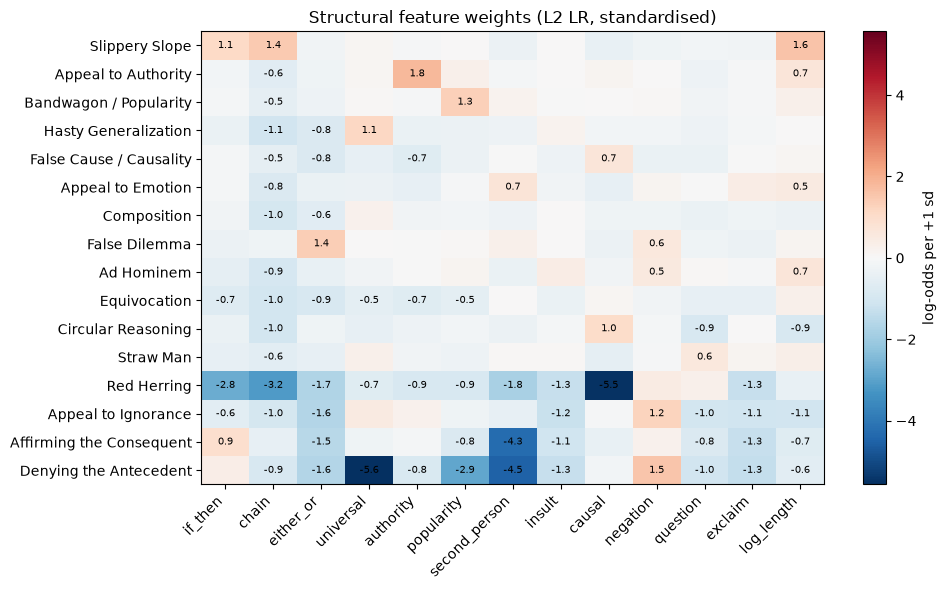

In [8]:
lr_s = [LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(S_tr, Y_tr[:, k]) for k in range(len(LABELS))]
Wst = pd.DataFrame(np.vstack([m.coef_[0] for m in lr_s]), index=LABELS, columns=FEATURE_NAMES)
Wst.to_csv(RESULTS / "structural_coefficients.csv")
fig, ax = plt.subplots(figsize=(10, 6))
lim = np.abs(Wst.values).max()
im = ax.imshow(Wst.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(FEATURE_NAMES))); ax.set_xticklabels(FEATURE_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
for i in range(Wst.shape[0]):
    for j in range(Wst.shape[1]):
        if abs(Wst.values[i, j]) > 0.5: ax.text(j, i, f"{Wst.values[i, j]:.1f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, label="log-odds per +1 sd"); ax.set_title("Structural feature weights (L2 LR, standardised)")
plt.tight_layout(); plt.savefig(FIGURES / "structural_coefficients.png", dpi=150); plt.show()

Each pattern's largest positive weight falls on the fallacy its definition predicts:
`chain` and `if_then` → Slippery Slope, `either_or` → False Dilemma, `authority` → Appeal to
Authority, `popularity` → Bandwagon, `universal` → Hasty Generalization, `causal` → Circular
Reasoning / False Cause, `negation` → Denying the Antecedent. `insult` → Ad Hominem is
positive but weak (≈0.4): this dataset's ad hominems are rarely name-calling. `log_length` →
Slippery Slope is a length shortcut (chain arguments are long), not a reasoning feature.
The large *negative* weights on the rarest labels (Red Herring, Denying the Antecedent) come
from balanced weighting of very few positives and should not be over-read.

So the structural features carry genuine signal about argument form, yet they add little on
top of n-grams, because n-grams already contain the same cue words, plus the topic shortcuts.

In [9]:
use_struct = float(srow.cv_macro_f1.max()) > base_cv
sel["TFIDF+Structural-SVM"] = {"model": f"TF-IDF + structural (w={w_best:g}) Linear SVM", "weight": w_best,
                               "C": s_cfg["C"], "class_weight": s_cfg["class_weight"],
                               "cv_macro_f1": float(srow.cv_macro_f1.max()), "beats_tfidf_only_in_cv": bool(use_struct)}
print("structural block improves CV macro-F1:", use_struct)

structural block improves CV macro-F1: True


## 9.5 (G4) Critical boundary arguments: active support vectors
For a linear SVM with decision function f(x) = wᵀx + b, a training argument i is an
**active support vector** when yᵢ f(xᵢ) ≤ 1, i.e. it lies on or inside the margin. Only these
arguments determine w. Validation arguments with |f(x)| close to 0 are the boundary cases.

In [10]:
svm = linear_svm(s_cfg["C"], cw).fit(A, Y_tr)
brow, cases = [], []
for lab in FOCUS:
    k = LABELS.index(lab); est = svm.estimators_[k]
    y = np.where(Y_tr[:, k] == 1, 1, -1); m_tr = est.decision_function(A)
    sv = y * m_tr <= 1
    brow.append({"fallacy": lab, "train positives": int((y == 1).sum()), "support vectors": int(sv.sum()),
                 "SV share of train": sv.mean(), "positives that are SVs": (sv & (y == 1)).sum() / (y == 1).sum()})
    m_va = est.decision_function(B)
    for i in np.argsort(np.abs(m_va))[:4]:
        cases.append({"fallacy": lab, "margin f(x)": round(float(m_va[i]), 3), "truly this fallacy": bool(Y_va[i, k]),
                      "all true labels": S["val"][2].fallacies.iloc[i], "argument": X_va.iloc[i]})
pd.DataFrame(brow).round(3)

,fallacy,train positives,support vectors,SV share of train,positives that are SVs
0,Slippery Slope,3925,5565,0.388,0.390
1,Ad Hominem,957,4829,0.337,0.783
2,False Dilemma,1080,4975,0.347,0.550


In [11]:
pd.set_option("display.max_colwidth", 220)
boundary = pd.DataFrame(cases); boundary.to_csv(RESULTS / "boundary_arguments_val.csv", index=False); boundary

,fallacy,margin f(x),truly this fallacy,all true labels,argument
0,Slippery Slope,-0.000,True,Slippery Slope,"Dr. Smith, a renowned nutritionist, says that eating one apple a day keeps the doctor away. Therefore, if you eat an apple daily, you will never get sick and can avoid all medical expenses forever."
1,Slippery Slope,-0.005,False,Bandwagon / Popularity; Ad Hominem,"Since polls show most people believe in climate change and scientists say it's urgent, we must immediately ban all fossil fuels even if it causes economic collapse—after all, anyone who disagrees is probably funded b..."
2,Slippery Slope,0.006,True,Slippery Slope; Hasty Generalization,"Since my friend started jogging daily and lost weight, everyone must jog to lose weight, and if you don't jog, you'll never be healthy."
3,Slippery Slope,0.007,False,Appeal to Authority; Bandwagon / Popularity,"Dr. Smith, a famous psychologist, claims that 95% of people who meditate daily become happier. Therefore, if you start meditating, you will definitely become happier because everyone is doing it and experts say it wo..."
4,Ad Hominem,0.007,False,Slippery Slope; Equivocation,"My friend who studies philosophy says that since 'free will' could mean different things in different contexts, and since neuroscience shows our decisions are preceded by brain activity, we therefore cannot trust any..."
5,Ad Hominem,0.010,False,Hasty Generalization,"My friend John failed the exam, proving he's incompetent at everything. After all, everyone knows he always struggles with math, so why trust him on anything?"
6,Ad Hominem,0.010,False,Bandwagon / Popularity; False Dilemma,"You should join this fitness program - everyone in our office is doing it and those who don't participate are clearly not serious about their health, so you must sign up now to avoid being ostracized."
7,Ad Hominem,0.011,False,Slippery Slope; Appeal to Emotion; False Dilemma,"My psychic advisor, who predicted the 2020 stock crash, says that if you don't buy his 'lucky crystals' today, you will face financial ruin just like all those stubborn skeptics who ignored his warnings. It's common ..."
8,False Dilemma,-0.010,False,Appeal to Emotion,"If you truly care about your children's education, you'll vote for this school funding proposal. How could you look them in the eye if you don't support better schools?"
9,False Dilemma,-0.010,False,Appeal to Authority,"My professor said that regular exercise is beneficial, so you must join our expensive gym membership because it's the only way to get healthy."


Boundary arguments mix the cues of several fallacies, e.g. an expert ("Dr. Smith, a renowned
nutritionist") followed by an if–then chain, or an insult combined with "everyone knows".
They are exactly the cases where the silver labels are also least certain. 34–39% of the
training arguments are support vectors for each focus label, and 78% of the Ad Hominem
positives are. The classes are far from separable with a wide margin in this feature space,
so the boundary rests on many arguments, not a few prototypical ones.

## 9.6 (G6) Proper-noun removal with NLTK
NLTK's averaged-perceptron POS tagger marks proper nouns as NNP / NNPS; we replace those
tokens with a placeholder. The tagger is fixed (not fitted on our data), so applying it to
train and val cannot leak. Compared with the capitalisation heuristic used in notebook 06.

In [12]:
import nltk
for res, path in [("averaged_perceptron_tagger_eng", "taggers/averaged_perceptron_tagger_eng"), ("punkt_tab", "tokenizers/punkt_tab")]:
    try: nltk.data.find(path)
    except LookupError: nltk.download(res, quiet=True)

def mask_nnp(text):
    toks = nltk.word_tokenize(text)
    return " ".join("propername" if tag in ("NNP", "NNPS") else w for w, tag in nltk.pos_tag(toks))

print(mask_nnp("Famous chef Gordon Ramsay recommended it, and Dr. Smith from Harvard agrees."))
t = time.time(); tr_nnp = [mask_nnp(x) for x in X_tr]; va_nnp = [mask_nnp(x) for x in X_va]
print(f"tagged {len(tr_nnp) + len(va_nnp)} arguments in {time.time() - t:.0f}s")
n_masked = np.mean([x.count("propername") > 0 for x in tr_nnp])
print(f"share of training arguments with at least one proper noun masked: {n_masked:.1%}")
prow = []
for name, (a, b) in {"no masking": (X_tr, X_va),
                     "capitalisation heuristic (nb06)": ([mask_proper_nouns(x) for x in X_tr], [mask_proper_nouns(x) for x in X_va]),
                     "NLTK NNP/NNPS": (tr_nnp, va_nnp)}.items():
    v = word_tfidf(ngram_range=(1, 2)); P = linear_svm(s_cfg["C"], cw).fit(v.fit_transform(a), Y_tr).predict(v.transform(b))
    prow.append({"preprocessing": name, **{k: scores(Y_va, P)[k] for k in ["macro_f1", "micro_f1"]}})
g6 = pd.DataFrame(prow); g6.round(4)

Famous chef propername propername recommended it , and propername propername from propername agrees .


tagged 16109 arguments in 13s
share of training arguments with at least one proper noun masked: 28.9%


,preprocessing,macro_f1,micro_f1
0,no masking,0.8229,0.8335
1,capitalisation heuristic (nb06),0.8235,0.8326
2,NLTK NNP/NNPS,0.8096,0.8287


The NLTK tagger masks more than names: capitalised common nouns and some sentence-initial
words are also tagged NNP, and it masks tokens in 29% of training arguments. That removes
some useful words, so macro-F1 *drops* slightly, while the narrower capitalisation heuristic
is neutral. Either way the proposal's expectation, that named entities are a major shortcut,
is not borne out: proper nouns are not where this model's shortcuts live; topic words are
(notebooks 06 and 08). We keep the unmasked text for the final models and report this as an
ablation.

## 9.7 (G7) Binary detection of the three focus fallacies, with accuracy vs an imbalanced baseline
The proposal planned to detect Ad Hominem, False Dilemma and Slippery Slope "alongside valid
arguments". **The dataset contains no valid (fallacy-free) arguments**, so that comparison is
impossible here. The closest honest version: one dedicated binary detector per focus
fallacy (present vs absent among other fallacies), reported with plain accuracy next to the
majority-class baseline, as the proposal asked, plus imbalance-aware metrics.

In [13]:
grow = []
for lab in FOCUS:
    k = LABELS.index(lab)
    m = LinearSVC(C=s_cfg["C"], class_weight=cw, max_iter=20000).fit(A, Y_tr[:, k])
    p, s = m.predict(B), m.decision_function(B)
    grow.append({"fallacy": lab, "prevalence": Y_va[:, k].mean(), "majority-class accuracy": 1 - Y_va[:, k].mean(),
                 "SVM accuracy": accuracy_score(Y_va[:, k], p), "balanced accuracy": balanced_accuracy_score(Y_va[:, k], p),
                 "F1": f1_score(Y_va[:, k], p), "average precision": average_precision_score(Y_va[:, k], s)})
g7 = pd.DataFrame(grow); g7.round(3)

,fallacy,prevalence,majority-class accuracy,SVM accuracy,balanced accuracy,F1,average precision
0,Slippery Slope,0.277,0.723,0.938,0.931,0.891,0.959
1,Ad Hominem,0.073,0.927,0.964,0.881,0.762,0.832
2,False Dilemma,0.079,0.921,0.969,0.875,0.794,0.857


For Ad Hominem a detector that always answers "absent" is already ~93% accurate, so the
SVM's accuracy looks much better than it is. Balanced accuracy (mean of the two recalls) and
F1 show the real gain over the baseline. The test-split version of this table is in
notebook 10.

In [14]:
sel["focus_binary"] = {"fallacies": FOCUS, "model": "LinearSVC per fallacy", "C": s_cfg["C"], "class_weight": s_cfg["class_weight"]}
sel_path.write_text(json.dumps(sel, indent=2, default=float))
out = {"prevalence_max_gap": float(prev["max |gap|"].max()), "kappa_X": float(kappa), "kappa_gram": float(kappa ** 2),
       "corr_pairs_095": len(pairs), "top_corr_pairs": [(names[i], names[j], float(up[i, j])) for i, j in pairs[:5]],
       "cv_best": best_cv.to_dict("records"), "cv_changed": changed, "structural_cv": srow.to_dict("records"),
       "structural_val": g1.to_dict("records"), "boundary_summary": pd.DataFrame(brow).to_dict("records"),
       "boundary_cases": boundary.to_dict("records"), "nnp_ablation": g6.to_dict("records"),
       "nnp_share": float(n_masked), "focus_binary_val": g7.to_dict("records")}
(RESULTS / "proposal_items_val.json").write_text(json.dumps(out, indent=2, default=float)); print("saved")

saved
